# Sleep Stage Classification from Single-Channel EEG Band Power/Spectral Analysis

Electroencephalography (EEG) records the brain’s electrical activity through scalp electrodes. Over a night, the brain cycles through Wake, light sleep (N1, N2), deep sleep (N3) and REM.

| Stage | Name | What's happening |
|-------|------|------------------|
| W  | Wake | Awake, alert |
| N1 | Light sleep | Drifting off, easy to wake |
| N2 | True sleep | Sleep spindles appear |
| N3 | Deep sleep | Slow big waves (delta) |
| R  | REM | Dreaming, eyes moving |

Each stage has a characteristic rhythm: deep sleep is dominated by slow delta waves, and wakefulness by faster beta activity. Sleep specialists traditionally label these stages by hand in 30-second windows (“epochs”)

### Objective
The notebook automates that labelling on a real overnight recording from the Sleep-EDF dataset (PhysioNet). It filters a single EEG channel (Fpz-Cz) to 0.5–30 Hz and cuts the night into 30-second epochs. For each epoch it computes delta, theta, alpha and beta band power plus a theta/alpha ratio, and trains a Random Forest to predict the stage. It uses a block-wise train/test split to avoid leakage between neighbouring epochs. It evaluates with a confusion matrix and per-stage metrics, then draws true versus predicted hypnograms.


In [1]:
!pip install mne -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 10.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
Done installing!


In [2]:
import mne
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import welch
from scipy.integrate import simpson

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import warnings
warnings.filterwarnings('ignore')
mne.set_log_level('WARNING')


All tools loaded!



## 3. Download Data

We're using the **Sleep-EDF dataset** from PhysioNet. It contains overnight EEG recordings

Each recording has two files:
- **PSG file** — the raw EEG signal
- **Hypnogram file** — the labels

We download 1 subject to keep it simple.

In [3]:
from mne.datasets.sleep_physionet.age import fetch_data

# Download 1 subject, 1 recording night
# MNE handles the download automatically from PhysioNet
print("Downloading data... (this takes ~1 minute the first time)")

files = fetch_data(subjects=[0], recording=[1])

# files[0] = EEG recording
# files[1] = sleep stage labels
psg_file = files[0][0]   # PSG = PolysomnoGraphy (the EEG)
hyp_file = files[0][1]   # Hypnogram (the labels)

print(f"Downloaded! EEG file: {psg_file.split('/')[-1]}")
print(f"Labels file: {hyp_file.split('/')[-1]}")

Downloaded! EEG file: SC4001E0-PSG.edf
Labels file: SC4001EC-Hypnogram.edf



## 4. Load and Peek at the Data

**single-channel**, **filter**: 0.5–30 Hz.  


In [4]:
# Load the raw EEG file
raw = mne.io.read_raw_edf(psg_file, preload=True)

# Load the sleep stage labels
annotations = mne.read_annotations(hyp_file)
raw.set_annotations(annotations)

# Print basic info
print("=== Recording Info ===")
print(f"Channels available : {raw.ch_names}")
print(f"Sampling rate      : {raw.info['sfreq']} Hz")
print(f"  (= {raw.info['sfreq']} data points per second)")
print(f"Recording duration : {raw.times[-1]/3600:.1f} hours")
print(f"Sleep stage labels : {set(annotations.description)}")

=== Recording Info ===
Channels available : ['EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal', 'Resp oro-nasal', 'EMG submental', 'Temp rectal', 'Event marker']
Sampling rate      : 100.0 Hz
  (= 100.0 data points per second)
Recording duration : 22.1 hours
Sleep stage labels : {'Sleep stage 3', 'Sleep stage 4', 'Sleep stage ?', 'Sleep stage 1', 'Sleep stage 2', 'Sleep stage R', 'Sleep stage W'}


In [5]:
# Keep only the EEG channel we need
# 'EEG Fpz-Cz' is a standard electrode position used in sleep research
raw.pick_channels(['EEG Fpz-Cz'])

# Filter: keep only 0.5 to 30 Hz
# l_freq = low cutoff, h_freq = high cutoff
raw.filter(l_freq=0.5, h_freq=30.0)

print("Channel selected and filtered!")

Channel selected and filtered!
We now have 1 channel of clean EEG data.



## 5. Plot the Raw EEG Signal


Total data points : 7950000
= 22.1 hours × 100.0 Hz


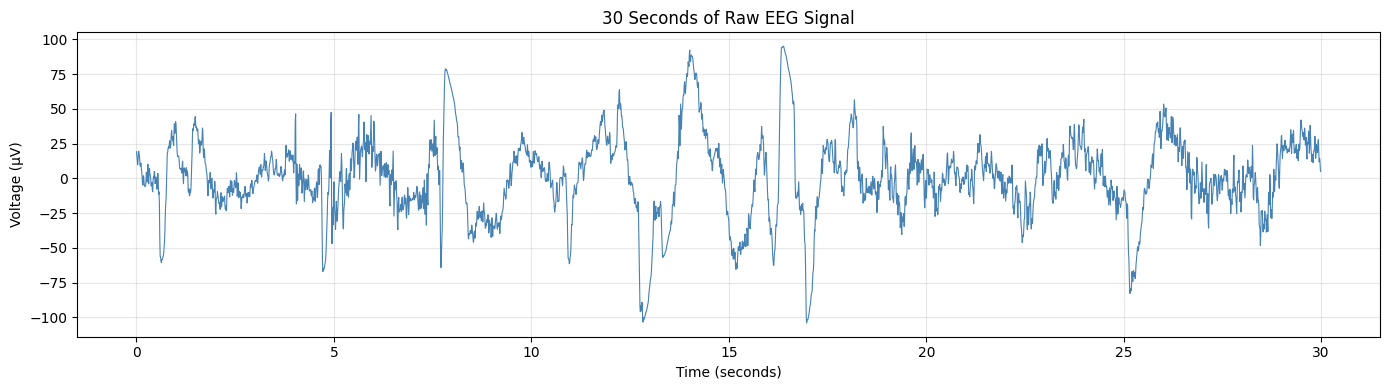

This is what brain electricity looks like!
Each wiggle is the brain's neurons firing.


In [6]:
# Get the raw data as a numpy array
# raw.get_data() returns shape: (n_channels, n_timepoints)
# [0] picks the first (and only) channel
eeg_signal = raw.get_data()[0]
time_axis  = raw.times              # time in seconds
sfreq      = raw.info['sfreq']      # sampling rate (100 Hz)

print(f"Total data points : {len(eeg_signal)}")
print(f"= {len(eeg_signal)/sfreq/3600:.1f} hours × {sfreq} Hz")

# Plot 30 seconds starting at minute 1 (= 60 seconds in)
start_sec = 60
end_sec   = 90

# Convert seconds to array indices
start_idx = int(start_sec * sfreq)
end_idx   = int(end_sec   * sfreq)

# * 1e6 converts Volts to microVolts (μV) — easier to read
segment = eeg_signal[start_idx:end_idx] * 1e6
t       = time_axis[start_idx:end_idx] - time_axis[start_idx]

plt.figure(figsize=(14, 4))
plt.plot(t, segment, color='steelblue', linewidth=0.8)
plt.xlabel("Time (seconds)")
plt.ylabel("Voltage (μV)")
plt.title("30 Seconds of Raw EEG Signal")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## 6. Slice into 30-Second Epochs

```
Full night EEG:  [----30s----][----30s----][----30s----] ...
Labels:              Wake         N1           N2        ...
```

In [7]:
STAGE_NAMES = {
    'Sleep stage W' : 'Wake',
    'Sleep stage 1' : 'N1',
    'Sleep stage 2' : 'N2',
    'Sleep stage 3' : 'N3',
    'Sleep stage 4' : 'N3',
    'Sleep stage R' : 'REM',
}

EPOCH_LENGTH = 30  # seconds per epoch

epochs = []
labels = []

for annotation in raw.annotations:
    stage = STAGE_NAMES.get(annotation['description'])
    if stage is None:
        continue


    # duration // EPOCH_LENGTH tells us how many 30s windows it covers.
    n_epochs_in_block = int(annotation['duration'] // EPOCH_LENGTH)

    for e in range(n_epochs_in_block):
        t_start = annotation['onset'] + e * EPOCH_LENGTH
        t_end   = t_start + EPOCH_LENGTH

        idx_start = int(t_start * sfreq)
        idx_end   = int(t_end   * sfreq)

        if idx_end > len(eeg_signal):
            continue

        epoch_data = eeg_signal[idx_start:idx_end]
        epochs.append(epoch_data)
        labels.append(stage)

X = np.array(epochs)
y = np.array(labels)

print(f"Total epochs created : {len(X)}")
print(f"Each epoch has shape : {X[0].shape} (= 30s × 100Hz)")
print()
print("Stage counts:")
for stage in ['Wake', 'N1', 'N2', 'N3', 'REM']:
    count = np.sum(y == stage)
    print(f"  {stage:5s} : {count} epochs = {count * 0.5:.0f} minutes")

Total epochs created : 2650
Each epoch has shape : (3000,) (= 30s × 100Hz)

Stage counts:
  Wake  : 1997 epochs = 998 minutes
  N1    : 58 epochs = 29 minutes
  N2    : 250 epochs = 125 minutes
  N3    : 220 epochs = 110 minutes
  REM   : 125 epochs = 62 minutes



## 7. Spectral Analysis

The result is a **power spectrum** — a graph with:
- X-axis: frequency (Hz)
- Y-axis: power (how strong that frequency is)

The brain has named frequency bands:

```
0.5 ──── 4 ──── 8 ──── 13 ──── 30  Hz
 |  Delta  | Theta | Alpha | Beta  |
 | (sleep) |(drows)|(relax)|(alert)|
```

N3 (deep sleep) has lots of Delta power. Wake has lots of Beta.  
So if we measure power in each band, we get features that separate the stages!

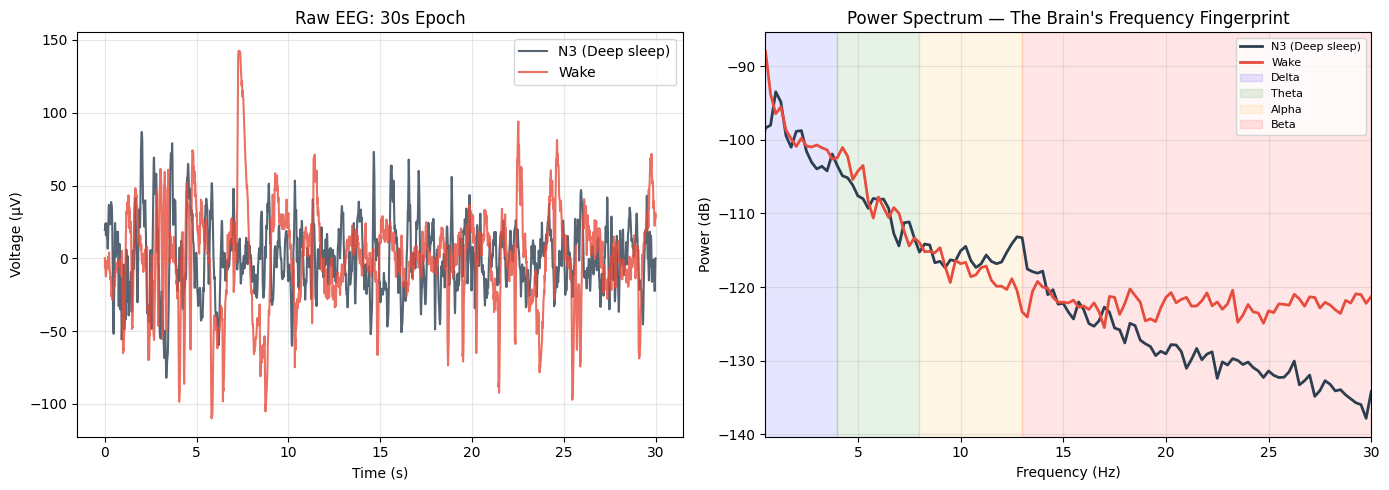

See how N3 has a huge peak on the LEFT (low frequencies = Delta)?
Wake has more power on the RIGHT (higher frequency = Beta) — now visible
relative to its own baseline, instead of being flattened by N3's delta peak.
THIS is the signature our model will learn to recognize.


In [8]:
# Pick one N3 epoch and one Wake epoch
n3_epoch   = X[y == 'N3'][0]    # first N3 epoch
wake_epoch = X[y == 'Wake'][0]  # first Wake epoch

# welch() computes the power spectrum
# nperseg = how many samples per window (4 seconds worth)
freqs_n3,   psd_n3   = welch(n3_epoch,   sfreq, nperseg=int(sfreq * 4))
freqs_wake, psd_wake = welch(wake_epoch, sfreq, nperseg=int(sfreq * 4))

# Convert to dB so the huge delta peak doesn't visually flatten
# the higher-frequency bands to zero (they're real, just much smaller in raw power)
psd_n3_db   = 10 * np.log10(psd_n3)
psd_wake_db = 10 * np.log10(psd_wake)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: raw signal comparison
t30 = np.arange(len(n3_epoch)) / sfreq
axes[0].plot(t30, n3_epoch   * 1e6, color='#2C3E50', label='N3 (Deep sleep)', alpha=0.8)
axes[0].plot(t30, wake_epoch * 1e6, color='#E74C3C', label='Wake',            alpha=0.8)
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Voltage (μV)")
axes[0].set_title("Raw EEG: 30s Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Right plot: power spectrum — the KEY visualization
mask = freqs_n3 <= 30   # only show 0–30 Hz (freqs_n3/freqs_wake are identical bins here,
                        # since both use the same sfreq and nperseg)
axes[1].plot(freqs_n3[mask],   psd_n3_db[mask],   color='#2C3E50', label='N3 (Deep sleep)', linewidth=2)
axes[1].plot(freqs_wake[mask], psd_wake_db[mask], color='#E74C3C', label='Wake',            linewidth=2)

# Shade the frequency bands
axes[1].axvspan(0.5, 4,  alpha=0.1, color='blue',   label='Delta')
axes[1].axvspan(4,   8,  alpha=0.1, color='green',  label='Theta')
axes[1].axvspan(8,   13, alpha=0.1, color='orange', label='Alpha')
axes[1].axvspan(13,  30, alpha=0.1, color='red',    label='Beta')

axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Power (dB)")
axes[1].set_title("Power Spectrum — The Brain's Frequency Fingerprint")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)
axes[1].set_xlim(0.5, 30)

plt.tight_layout()
plt.show()

print("See how N3 has a huge peak on the LEFT (low frequencies = Delta)?")
print("Wake has more power on the RIGHT (higher frequency = Beta) — now visible")
print("relative to its own baseline, instead of being flattened by N3's delta peak.")
print("THIS is the signature our model will learn to recognize.")

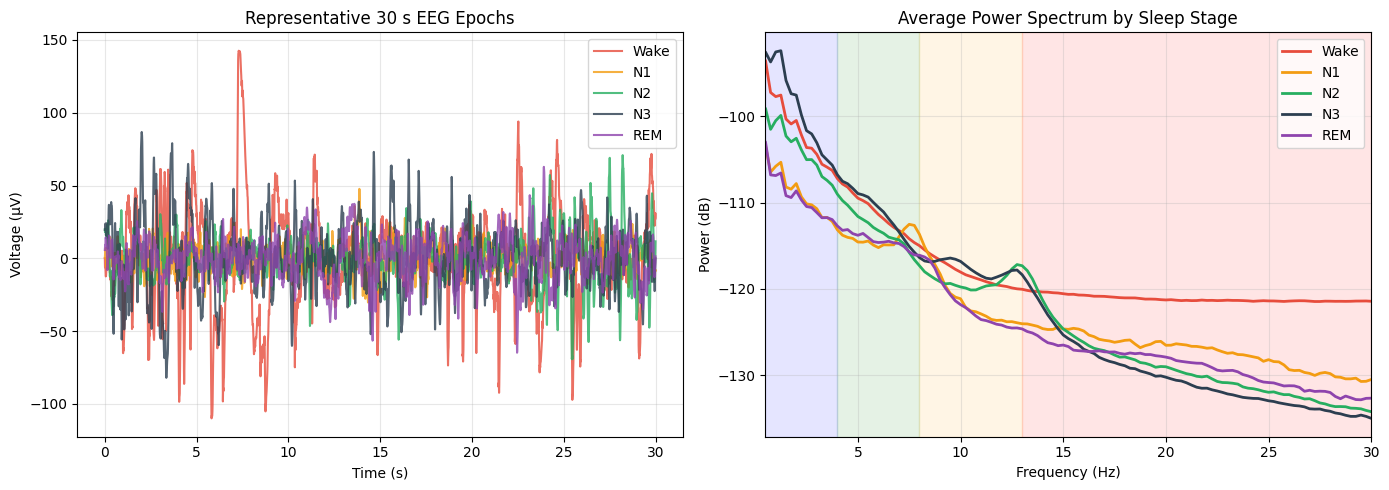

In [9]:
# Average PSD for each sleep stage
stages = ['Wake', 'N1', 'N2', 'N3', 'REM']
colors = {
    'Wake': '#E74C3C',
    'N1':   '#F39C12',
    'N2':   '#27AE60',
    'N3':   '#2C3E50',
    'REM':  '#8E44AD'
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Raw EEG
for stage in stages:
    epoch = X[y == stage][0]
    t30 = np.arange(len(epoch)) / sfreq
    axes[0].plot(t30, epoch * 1e6,
                 label=stage,
                 color=colors[stage],
                 alpha=0.8)

axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Voltage (μV)")
axes[0].set_title("Representative 30 s EEG Epochs")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Right: Average PSD
for stage in stages:

    stage_epochs = X[y == stage]

    psds = []
    for epoch in stage_epochs:
        freqs, psd = welch(epoch, sfreq,
                           nperseg=int(sfreq * 4))
        psds.append(10 * np.log10(psd))

    mean_psd = np.mean(psds, axis=0)

    mask = freqs <= 30
    axes[1].plot(freqs[mask], mean_psd[mask],
                 label=stage,
                 color=colors[stage],
                 linewidth=2)

# Frequency bands
axes[1].axvspan(0.5, 4,  alpha=0.1, color='blue')
axes[1].axvspan(4,   8,  alpha=0.1, color='green')
axes[1].axvspan(8,   13, alpha=0.1, color='orange')
axes[1].axvspan(13,  30, alpha=0.1, color='red')

axes[1].set_xlim(0.5, 30)
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Power (dB)")
axes[1].set_title("Average Power Spectrum by Sleep Stage")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 8. Extract Features from Every Epoch

For each 30s window, we compute **5 numbers**:
- Delta power (0.5–4 Hz)
- Theta power (4–8 Hz)
- Alpha power (8–13 Hz)
- Beta power (13–30 Hz)
- Theta/Alpha ratio (useful for detecting drowsiness)

These 5 values become the **features** the model learns from.

```
30s of EEG signal  →  [delta, theta, alpha, beta, ratio]  →  "N3"
(3000 numbers)          (5 numbers = features)              (label)
```

In [10]:
# Define our frequency bands
BANDS = {
    'delta': (0.5, 4),
    'theta': (4,   8),
    'alpha': (8,  13),
    'beta' : (13, 30),
}

def get_bandpower(signal, sfreq, low_hz, high_hz):
    """
    Compute the power of a signal within a frequency range.

    How it works:
    1. welch() breaks the signal into its frequency components
    2. We find which frequencies fall in our band (low_hz to high_hz)
    3. We sum up the power in just those frequencies
    """
    # Compute the power spectrum
    freqs, psd = welch(signal, sfreq, nperseg=int(sfreq * 4))

    # Find which frequency bins are within our band
    in_band = (freqs >= low_hz) & (freqs <= high_hz)

    # Integrate (sum) the power in that band
    power = simpson(psd[in_band], x=freqs[in_band])
    return power


def extract_features(epochs):
    """
    Take a list of 30s EEG epochs.
    Return a list of 5 features per epoch.
    """
    all_features = []

    for i, epoch in enumerate(epochs):

        # Compute power in each band
        delta = get_bandpower(epoch, sfreq, 0.5, 4)
        theta = get_bandpower(epoch, sfreq, 4,   8)
        alpha = get_bandpower(epoch, sfreq, 8,  13)
        beta  = get_bandpower(epoch, sfreq, 13, 30)

        # Theta/Alpha ratio — high when drowsy
        theta_alpha_ratio = theta / (alpha + 1e-10)

        # Pack into a list of 5 numbers
        features = [delta, theta, alpha, beta, theta_alpha_ratio]
        all_features.append(features)

        # Progress update every 100 epochs
        if (i + 1) % 100 == 0:
            print(f"  Processed {i+1}/{len(epochs)} epochs...")

    return np.array(all_features)


print("Extracting features from all epochs...")
print("(This takes ~1-2 minutes)")
X_features = extract_features(X)

feature_names = ['delta', 'theta', 'alpha', 'beta', 'theta_alpha_ratio']

print(f"\nDone!")
print(f"Feature matrix shape: {X_features.shape}")
print(f"= {X_features.shape[0]} epochs × {X_features.shape[1]} features")
print(f"\nFirst epoch's features:")
for name, val in zip(feature_names, X_features[0]):
    print(f"  {name:20s} = {val:.4f}")

Extracting features from all epochs...
(This takes ~1-2 minutes)
  Processed 100/2650 epochs...
  Processed 200/2650 epochs...
  Processed 300/2650 epochs...
  Processed 400/2650 epochs...
  Processed 500/2650 epochs...
  Processed 600/2650 epochs...
  Processed 700/2650 epochs...
  Processed 800/2650 epochs...
  Processed 900/2650 epochs...
  Processed 1000/2650 epochs...
  Processed 1100/2650 epochs...
  Processed 1200/2650 epochs...
  Processed 1300/2650 epochs...
  Processed 1400/2650 epochs...
  Processed 1500/2650 epochs...
  Processed 1600/2650 epochs...
  Processed 1700/2650 epochs...
  Processed 1800/2650 epochs...
  Processed 1900/2650 epochs...
  Processed 2000/2650 epochs...
  Processed 2100/2650 epochs...
  Processed 2200/2650 epochs...
  Processed 2300/2650 epochs...
  Processed 2400/2650 epochs...
  Processed 2500/2650 epochs...
  Processed 2600/2650 epochs...

Done!
Feature matrix shape: (2650, 5)
= 2650 epochs × 5 features

First epoch's features:
  delta              


## 9. Train the Model

In [11]:

BLOCK_EPOCHS = 40
groups = np.arange(len(X_features)) // BLOCK_EPOCHS

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)  # 5 folds -> 20% test
train_idx, test_idx = next(cv.split(X_features, y, groups))

X_train, X_test = X_features[train_idx], X_features[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print(f"Training set : {len(X_train)} epochs")
print(f"Testing set  : {len(X_test)} epochs")

# Create the model
# n_estimators = how many decision trees to build
# class_weight='balanced' counters the class imbalance (Wake is ~75% of epochs,
# N1 only ~2%): rare stages get a higher weight. It only affects training, and
# the test set keeps its natural distribution, so the evaluation stays honest.
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

# Train the model — it learns the patterns
print("\nTraining the model...")
model.fit(X_train, y_train)
print("Done!")

# Make predictions on test data
y_pred = model.predict(X_test)

# Check accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"\n Accuracy: {accuracy:.1%}")
print(f"   = the model got {accuracy:.1%} of test epochs correct")

Training set : 2090 epochs
Testing set  : 560 epochs

Training the model...
Done!

🎯 Accuracy: 90.5%
   = the model got 90.5% of test epochs correct



## 10. Results


In [12]:
# Classification report — precision, recall, F1 for each stage
print("Detailed Results Per Stage:")
print("=" * 50)
print(classification_report(y_test, y_pred))



Detailed Results Per Stage:
              precision    recall  f1-score   support

          N1       0.30      0.38      0.33         8
          N2       0.47      0.84      0.60        25
          N3       0.92      0.73      0.82        64
         REM       0.92      0.68      0.78        34
        Wake       0.96      0.96      0.96       429

    accuracy                           0.91       560
   macro avg       0.71      0.72      0.70       560
weighted avg       0.92      0.91      0.91       560


What these numbers mean:
  Precision : of all epochs we PREDICTED as X, how many actually were X?
  Recall    : of all epochs that ARE X, how many did we correctly find?
  F1-score  : balance between precision and recall (higher = better)


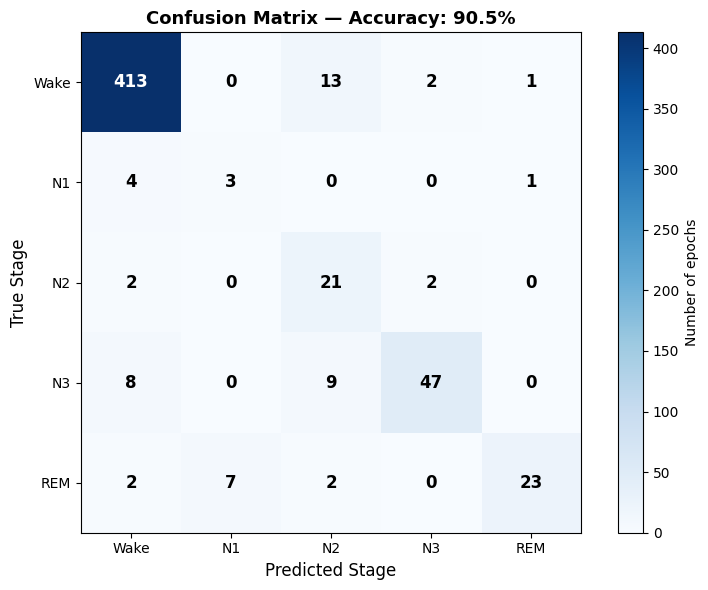

The DIAGONAL = correct predictions (we want these to be big)
OFF-diagonal = mistakes (ideally small)

N1 is usually the weakest — even human experts disagree on N1!


In [13]:
# Confusion matrix — visual grid of predictions vs truth
stage_order = ['Wake', 'N1', 'N2', 'N3', 'REM']

# Reorder to match stage_order
cm = confusion_matrix(y_test, y_pred, labels=stage_order)

plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation='nearest', cmap='Blues')
plt.colorbar(label='Number of epochs')

plt.xticks(range(len(stage_order)), stage_order)
plt.yticks(range(len(stage_order)), stage_order)
plt.xlabel("Predicted Stage", fontsize=12)
plt.ylabel("True Stage", fontsize=12)
plt.title(f"Confusion Matrix — Accuracy: {accuracy:.1%}", fontsize=13, fontweight='bold')

# Add the numbers inside each cell
for i in range(len(stage_order)):
    for j in range(len(stage_order)):
        plt.text(j, i, str(cm[i, j]),
                 ha='center', va='center',
                 color='white' if cm[i, j] > cm.max()/2 else 'black',
                 fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print("The DIAGONAL = correct predictions (we want these to be big)")
print("OFF-diagonal = mistakes (ideally small)")
print("\nN1 is usually the weakest — even human experts disagree on N1!")


## 11. Draw a Hypnogram

Healthy sleep looks like a wave — cycling between light and deep sleep,  
with REM periods that get longer toward morning.

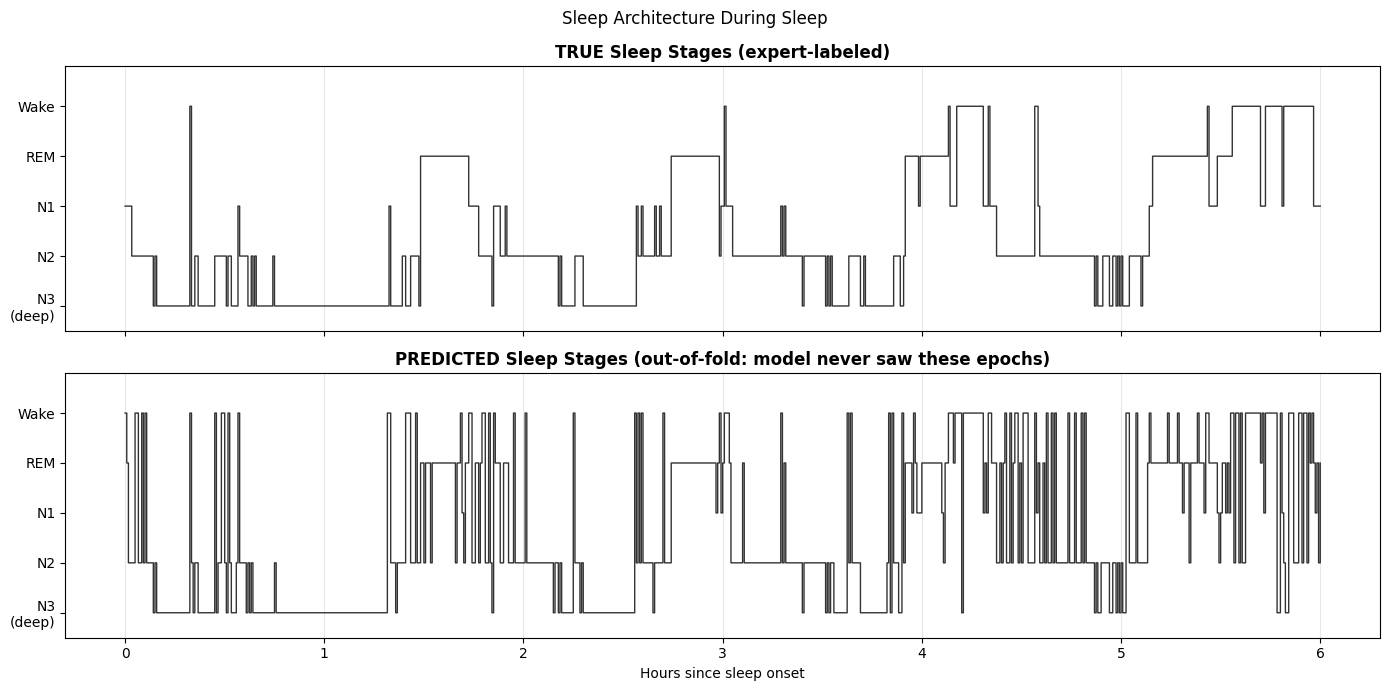

Notice: N3 (deep sleep) is concentrated early in the sleep period.
REM episodes become more frequent later in the sleep period, consistent with normal adult sleep.


In [14]:
# Predict the whole night WITHOUT showing the model epochs it trained on.
# Out-of-fold predictions: every block is predicted by a model that never saw it.
y_all_pred = cross_val_predict(
    RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'),
    X_features, y, groups=groups, cv=cv
)

stage_to_num = {
    'N3': 0,
    'N2': 1,
    'N1': 2,
    'REM': 3,
    'Wake': 4
}

# Map the true and predicted labels to numerical values for ALL epochs
true_nums = np.array([stage_to_num[s] for s in y])
pred_nums = np.array([stage_to_num[s] for s in y_all_pred])

# Find first and last non-Wake epoch
sleep_epochs = np.where(np.array(y) != 'Wake')[0]
start = sleep_epochs[0]
end = sleep_epochs[-1] + 1

# Crop data
true_plot = true_nums[start:end]
pred_plot = pred_nums[start:end]

# Time axis (hours since sleep started)
hours = np.arange(end - start) * 30 / 3600

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

for ax, nums, title in [
    (axes[0], true_plot, "TRUE Sleep Stages (expert-labeled)"),
    (axes[1], pred_plot, "PREDICTED Sleep Stages (out-of-fold: model never saw these epochs)")
]:
    ax.step(hours, nums, where='post', color='#333', linewidth=1)
    ax.set_yticks([0,1,2,3,4])
    ax.set_yticklabels(['N3\n(deep)', 'N2', 'N1', 'REM', 'Wake'])
    ax.set_ylim(-0.5, 4.8)
    ax.grid(True, axis='x', alpha=0.3)
    ax.set_title(title, fontweight='bold')

axes[1].set_xlabel("Hours since sleep onset")

plt.suptitle("Sleep Architecture During Sleep")
plt.tight_layout()
plt.show()
print("Notice: N3 (deep sleep) is concentrated early in the sleep period.")
print("REM episodes become more frequent later in the sleep period, consistent with normal adult sleep.")

In [15]:
# Final summary printout
print("=" * 45)
print("        YOUR MODEL IN NUMBERS")
print("=" * 45)
print(f"Total epochs      : {len(X)}")
print(f"Features per epoch: 5 (bandpower values)")
print(f"Model             : Random Forest")
print(f"Test accuracy     : {accuracy:.1%}")
print()
print("Stage breakdown:")
for stage in ['Wake', 'N1', 'N2', 'N3', 'REM']:
    n = np.sum(y == stage)
    mins = n * 0.5
    bar = '|' * (n // 20)
    print(f"  {stage:5s} {bar} {n} epochs ({mins:.0f} min)")

        YOUR MODEL IN NUMBERS
Total epochs      : 2650
Features per epoch: 5 (bandpower values)
Model             : Random Forest
Test accuracy     : 90.5%

Stage breakdown:
  Wake  ||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||| 1997 epochs (998 min)
  N1    || 58 epochs (29 min)
  N2    |||||||||||| 250 epochs (125 min)
  N3    ||||||||||| 220 epochs (110 min)
  REM   |||||| 125 epochs (62 min)


The Random Forest reached 90.5% accuracy on the held-out test set (560 epochs from a block-wise split of 2,650 epochs, one subject, one night). Accuracy is inflated by class imbalance, though. Wake makes up about 75% of the recording, and 429 of the 560 test epochs were Wake, so always predicting Wake would already score roughly 77%. The macro-averaged F1 of 0.70 is a better summary.

Wake and N3 were classified most reliably, matching the strong beta and delta power signatures of those stages. N1 was the weakest (F1 0.33), which the notebook attributes to N1 being a brief transitional stage that human scorers also disagree on. N2 had high recall but low precision, so other stages were often mislabelled as N2.

These results come from a single subject and night with only 5 band-power features, and the N1 and N2 test sets are very small (8 and 25 epochs). They should be read as a proof of concept, not a validated sleep-staging system. The notebook also draws a true versus predicted hypnogram using out-of-fold predictions, so the model is never scored on epochs it trained on.